---
exports:
  - format: pdf
    template: lapreprint-typst
    id: notes-12b
downloads:
  - id: notes-12b
    title: PDF notes
  - file: 12b_MCMC.ipynb
    title: Notebook
---

```{note} Install these packages first!
For today, we'll need two packages:
+ emcee: [installation instructions](https://emcee.readthedocs.io/en/stable/user/install/)
+ corner: [installation instructions](https://corner.readthedocs.io/en/latest/install/)

(Use `conda` if you have anaconda installed, otherwise use the `pip` method)
```

# MCMC for Inference
Our previous discussion of Markov Chain Monte Carlo was using Markov Chains to traverse a set of possible states, sampling new states and approving transitions to other states based on the favorability of those transitions. 

With MCMC, converging to the equilibrium solution can be rapid as steps are taken in the direction of more probable solutions, rather than having to traverse the entire range of possible configurations.

With a Bayesian inference framework, we can similarly use MCMC to efficiently traverse a parameter space of potential model solutions in order to determine the most probable model solutions for a given dataset.

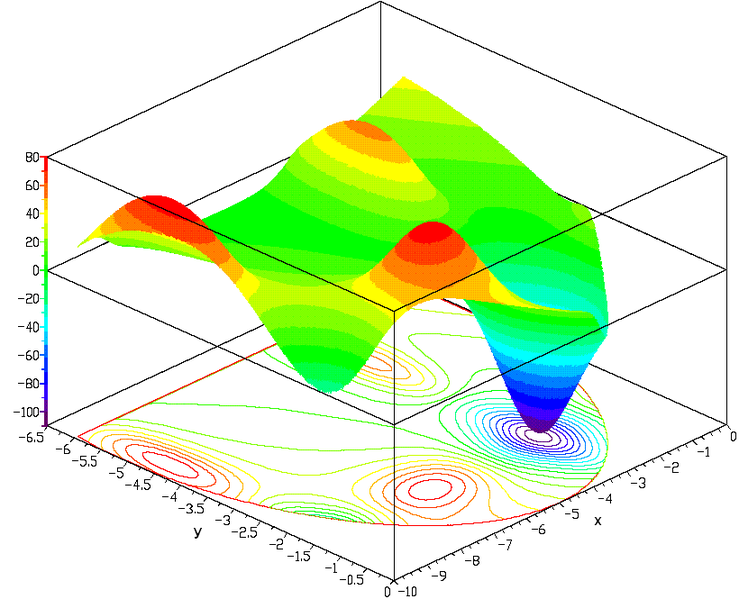



## Bayesian Inference 
The goal of Bayesian inference is an estimation of the posterior distribution of the parameters -- the underlying probability distribution of the model parameters.

The posterior distribution is given by Bayes' theorem:

$$ \Large 
p(\theta \mid \mathbf{y}) = \frac{p(\mathbf{y} \mid \mathbf{\theta}) \, p(\mathbf{\theta})}{p(\mathbf{y})}
$$

where:

- $\mathbf{\theta}$ represents the parameters we want to estimate,
- $\mathbf{y}$ represents the observed data,
- $p(\mathbf{\theta})$ is the prior probability, reflecting our beliefs about $\mathbf{\theta}$ 
- $p(\mathbf{y} \mid \mathbf{\theta})$ is the likelihood, the probability of observing the data given parameters $\mathbf{\theta}$,
- $p(\mathbf{y})$ is the evidence (or marginal likelihood), a normalizing *constant* ensuring the integral of the posterior (over $\mathbf{\theta}$) is unity.

The evidence is just the integral over the parameters $\mathbf{\theta}$, given by:

$$ \Large 
p(\mathbf{y}) = \int p(\mathbf{y} \mid \mathbf{\theta}) \, p(\mathbf{\theta}) \, d\mathbf{\theta}
$$

where it is the total probability of observing the data, integrating over all possible parameter values.

**However**, this integral is usually high-dimensional, non-analytical, or computationally expensive — especially for complex models.

Instead of computing $p(\mathbf{\theta} \mid \mathbf{y})$ exactly, with **sampling** we can use the ratios of posterior values, so the normalizing constant cancels out.

**Features of Bayesian Inference**:
+ Posterior distributions naturally provide confidence limits on parameter fits and easily capture non-normal uncertainties.
+ Easily see effects of model degeneracies in parameter correlations.
+ Traverse large multi-dimensional parameter space for complex or hierarchical models. 
+ Account for selection effects or data bias in the definition of the priors and likelihoods.
+ Use additional datasets to set priors and constraints i.e. *Today's posterior is tomorrow's prior*
+ Can squeeze more out of limited/unrepeatable datasets.

Let's see how to implement this procedure in practice.


### Ex: Spectral Line Fitting

#### Observed Data $y_i$
Say you have taken a spectrum and need to fit a line profile to the line.  
You have $N$ data points each corresponding to an Intensity at a given wavelength, with some error in $y$.

#### Model and Parameters $\theta$
Let's say you want to fitting a gaussian profile of spectral line with a simple model of the form:

$$ f(x) = A \exp{\left[-\frac{\left(x - x_0\right)^2}{2 w^2}\right]} \qquad \text{(Gaussian Profile)} $$

where 
* $A$ is the amplitude, 
* $x_0$ is the location of line center, and
* $w$ is the "spread" or width of the line.

These would be your model parameters: $\theta = [A, x_0, w]$


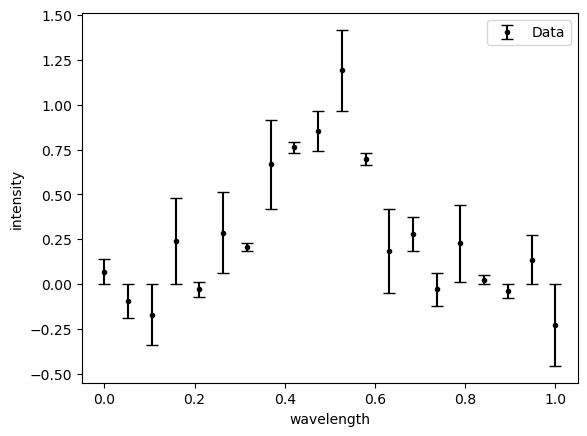

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import default_rng
import emcee
import corner
rng = np.random.default_rng()
x_data,y_data,e_data = np.loadtxt('../in-class/line_1.txt',unpack=True)
fig,ax = plt.subplots(1)
ax.errorbar(x_data, y_data, yerr=e_data, fmt="k.", capsize=4, label="Data")
ax.legend(loc="upper right")
ax.set_xlabel('wavelength')
ax.set_ylabel('intensity')

def model_gaussian(x, theta):
    """ make a model gaussian """
    A, x0, w = theta
    return A * np.exp(-0.5*(x-x0)**2/w/w)

```{note} Probability distributions are given in $\log$ space
For computing purposes, given the huge dynamic range of probabilities, it is computationally more tractable and accurate to provide probabilities in terms of the $log$ of their values. 

Consider: a multiplicative probability would become a sum in log space.
```

#### Priors $p(\theta)$
You would want to set your priors for the parameters $\theta$: a function that given some set of parameters $\theta$ provides the log of the PDF value. 

The simplest priors are uniform (or uninformed priors), where you only set the constraints on the range of the parameter values. 

Thus if the prior on the amplitude:  $A_{\rm min} < A < A_{\rm max}$ = 1, then the function should return $\ln(1) = 0$ if $A$ is in bounds and $\ln(0) = -\infty$ otherwise.

In [59]:
def ln_prior(theta):
    A, x0, w = theta
    if A_min < A < A_max and x0_min < x0 < x0_max and w_min < w < w_max:
        return 0.0
    return -np.inf

#### Likelihood $p(\mathbf{y} \mid \mathbf{\theta})$ or $L$
Now, just like with Metropolis-Hastings, our choice of probability function describes how we are sampling the parameter space. 

Our walkers walk towards regions of higher probability, so our choice of likelihood should describe how we are going to tell when the model is fitting better. 

for continuous data scattered symmetrically around a mean, we can express the total probability across all points as:
$$ P(\{y_i\} | \mu, \sigma) = \prod_{i=1}^N \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(y_i-\mu)^2}{2\sigma^2}\right)$$

if we take the expected mean $\mu$ for each point as the return from our model, then the likelihood describes the distance from the model, which you might recognize as the definition of $\chi^2$ [chi-squared](https://en.wikipedia.org/wiki/Chi-squared_test).

For independent parameters with normal distributions, we can prescribe a $\chi^2$ based likelihood function:

$$
\ln L = \text{constant} - \frac{1}{2} \sum_{i=1}^{N} {\dfrac{(y_i-f(x_i))^2}{\sigma_i^2}} \simeq - \frac{\chi^2}{2}
$$

where $f(x_i)$ is our model value and $\sigma_i$ is the data point error. 

Note that we can neglect the normalization constant, since probabilities are evaluated relative to one another in an MCMC scheme.

In other machine learning applications, the likelihood function is analogous to what is called the *loss function*. 

In [64]:
def ln_likelihood(theta,model,x_data,y_data):
    y_model = model(x_data,theta)
    chi2 = np.sum((y_data - y_model) ** 2.0 / e_data ** 2.0)
    return -chi2 / 2.0

#### Posterior $p(\theta \mid \mathbf{y})$
Now, all we need to do is tell the code how the posterior should be calculated (in log space: by adding together the priors and the likelihood for a a given set of parameters)

In [65]:
def ln_posterior(theta,model,x_data,y_data):
    lp = ln_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + ln_likelihood(theta,model,x_data,y_data)

### Using `emcee`
There are various MCMC algorithms (or samplers) out there. 

One algorithm that does not require much tuning is Goodman & Weare’s Affine Invariant Markov chain Monte Carlo Ensemble Sampler (<a href="https://msp.org/camcos/2010/5-1/p04.xhtml">Goodman & Weare 2010</a>), with a Python implementation: [the `emcee` module](https://emcee.readthedocs.io/en/stable/).

With `emcee` we need to define the following inputs:
+ Number of *walkers*, this is the number of Markov chains we are using. Each walker has to be given a starting position.
+ Number of dimensions, this is the number of parameters $\theta$ in the parameter space you are going to explore.
+ Starting positions of all walkers in the parameter space: this should be an array of shape: `(nwalkers,ndim)`
+ Number of steps, this is the total number of steps the walkers will take in each Markov chain.
+ Function to calculate the posteriors and its arguments. 

#### How does `emcee` make it's moves?
The design of `emcee` is a modification of the traditional Metropolis scheme: using the fact that there are multiple walkers, the next move is determined by using a technique called a "stretch" move.  

The next step for a walker at position $X_j$ will "stretch" along the straight line connecting $X_j$ to the position of a different nearby walker at $X_k$:

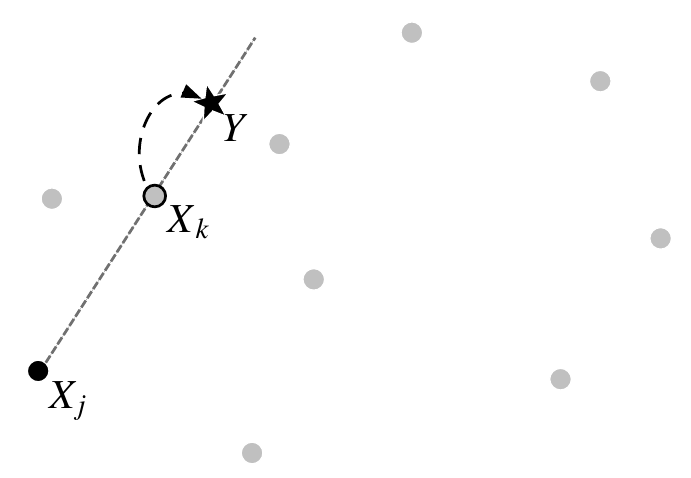

Let's set up the initial positions of our walkers. 

Technically, we can put them anywhere as the state an MCMC converges to doesn't care about the initial position, but putting them further away or outside of our prior bounds might not be a good idea in terms of the time it will take to converge.

In [ ]:
x_data,y_data,e_data = np.loadtxt('../in-class/line_1.txt',unpack=True)

# set the prior bounds
A_min, A_max = 0.9, 1.4
x0_min, x0_max = 0.45, 0.55
w_min, w_max = 0.05,0.25

theta_bounds = [(A_min,A_max),(x0_min,x0_max),(w_min,w_max)]
model=model_gaussian

# set the initial positions
def init_pos(theta_bounds,nwalkers):
    ndim = len(theta_bounds)
    pos = np.zeros((nwalkers,ndim))
    for i in range(ndim):
        min_,max_ = theta_bounds[i]
        pos[:,i] = rng.uniform(min_,max_,nwalkers)
    return pos

nwalkers = 32
ndim = 3
pos = init_pos(theta_bounds,nwalkers)
print(pos.shape)



(32, 3)


Next, we define the outputs of the `emcee` sampler as the `sampler` object, use the `run_mcmc` method and then we can plot the results of our chains.

When we use `get_chain` we get an object with the parameter values at each step for all the walkers in our system of shape: `(nsteps,nwalkers,ndim)`

100%|██████████| 5000/5000 [00:01<00:00, 2773.45it/s]

(5000, 32, 3)


Text(0.5, 0, 'step number')

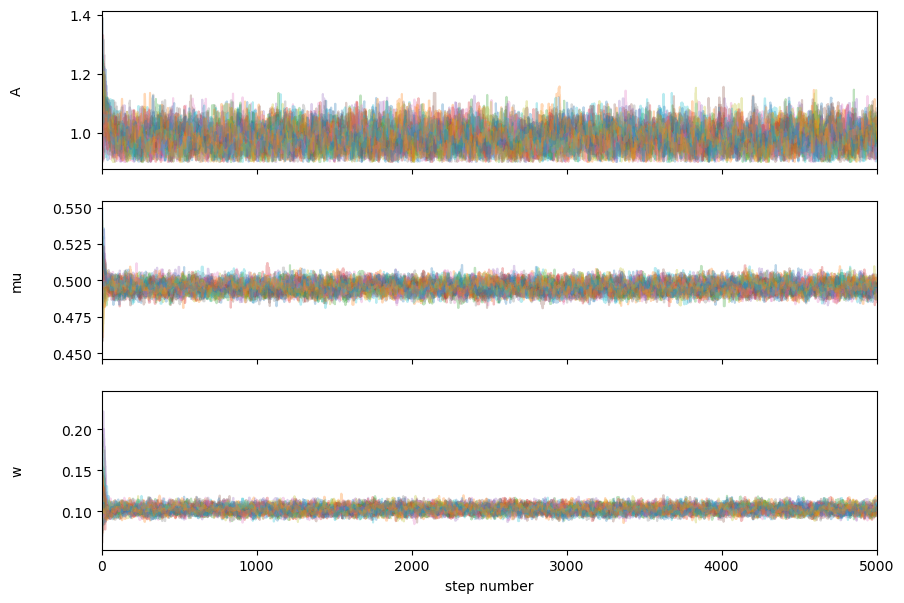

In [95]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, ln_posterior, args=(model,x_data,y_data))
sampler.run_mcmc(pos, 5000, progress=True)

fig, axes = plt.subplots(3, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
print(samples.shape)
labels = ["A", "mu", "w"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)
axes[-1].set_xlabel("step number")

Now, we want to construct our samples of the posterior distributions for each parameter. 

Typically, we'll want to do two things to make sure our samples are not related to the numerics of the problem. 
+ Discard the early steps in which the distribution is not yet converged -- called the "burn-in" period
+ Sample at some regular frequency to avoid periodicity

In [75]:
help(sampler.get_chain)

Help on method get_chain in module emcee.ensemble:

get_chain(**kwargs) method of emcee.ensemble.EnsembleSampler instance
    Get the stored chain of MCMC samples

    Args:
        flat (Optional[bool]): Flatten the chain across the ensemble.
            (default: ``False``)
        thin (Optional[int]): Take only every ``thin`` steps from the
            chain. (default: ``1``)
        discard (Optional[int]): Discard the first ``discard`` steps in
            the chain as burn-in. (default: ``0``)

    Returns:
        array[..., nwalkers, ndim]: The MCMC samples.



For this we can typically ask about the auto-correlation time: the number of steps in between which the chain "forgets" entirely forgets it's previous states.

In [96]:
tau = sampler.get_autocorr_time()
print(tau)

[37.55246738 35.11861882 36.73799015]


So here we:
+ Define the initial burn-in period as double or triple the longest autocorrelation time
+ Take samples regularly at roughly half the average autocorrelation time

Then we take those final samples as our sample of posteriors and plot a corner plot of the distributions.

This data was generated synthetically, so the true parameter values were:
$$ \theta= (1, 0.5, 0.1) $$

Which we can compare here:

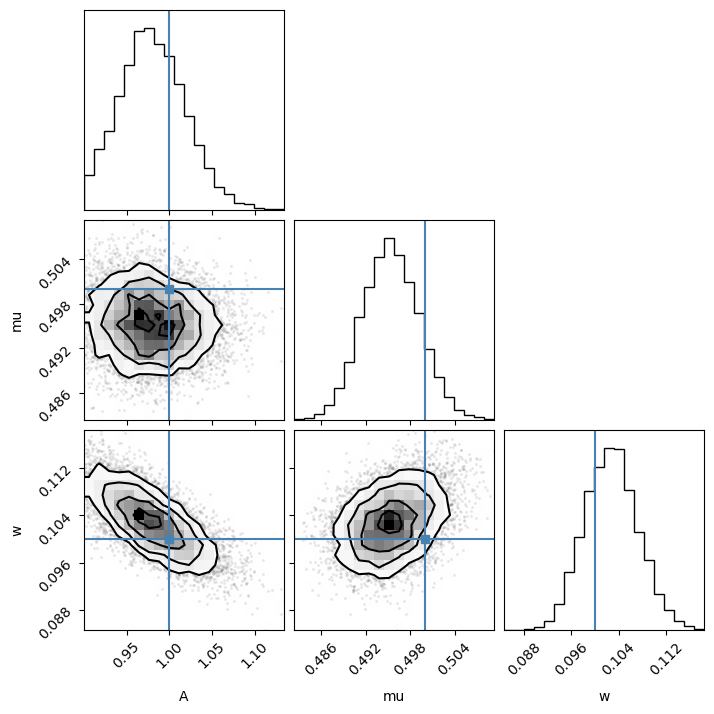

In [97]:
flat_samples = sampler.get_chain(discard=100, thin=20, flat=True)

true_theta = [1,0.5,0.1]
fig = corner.corner(flat_samples, labels=labels,truths=true_theta)


We can also get at the confidence intervals to report our final solution straight from the posteriors.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

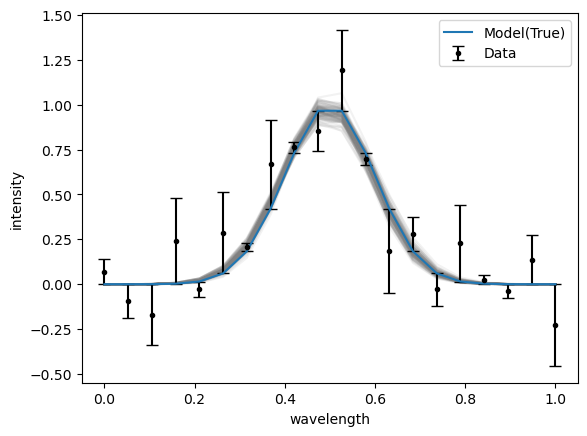

In [ ]:
from IPython.display import display, Math

fig,ax = plt.subplots(1)
inds = np.random.randint(len(flat_samples), size=100)
for ind in inds:
    sample = flat_samples[ind]
    ax.plot(x_data,model(x_data,sample),color='gray',alpha=0.1)


ax.errorbar(x_data, y_data, yerr=e_data, fmt="k.", capsize=4, label="Data")
ax.plot(x_data,model(x_data,true_theta),label='Model(True)')
ax.legend(loc="upper right")
ax.set_xlabel('wavelength')
ax.set_ylabel('intensity')


labels = ["A", "mu", "w"]
parameters = {}
for i in range(ndim):
    results = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(results)
    txt = r"\mathrm{{{3}}} = {0:.3f}_{{-{1:.3f}}}^{{{2:.3f}}}"
    parameters[labels[i]] = results[1] #parameters dictionary now contains best fit values
    txt = txt.format(results[1], q[0], q[1], labels[i])
    display(Math(txt))


For any given model, when you run the algorithm, how well it performs will vary based on:
+ Number of walkers: more walkers = more coverage of the parameter space early on
+ Number of steps: more steps = larger sample for more accurate posteriors
+ Initial locations of walkers: the closer they are to the solution, the faster the algorithm converges (unless your likelihood space is very funky)
+ Choice of priors: determine the shape of your posteriors, setting up a constraint on the prior should generally come from some reasoning around your model/situation not from a desire to tune the fits.

## Model Selection
Our posteriors tell us about the probability distribution of our model parameters given some dataset. 

However, the posteriors alone do not tell us about whether that particular model is true or not!

In fact, if we want to differentiate between models, we need to understand which one is more likely. 

We can use some metrics to overall describe how well a particular model fits, but these are to be used relative to one another. i.e. you need to perform a fit for both models.

### Bayesian Information Criterion (BIC)
For $N$ data points, a model with $k$ parameters and log-likelihood, the BIC is defined as: 
$$\text{BIC} = k \ln N - 2\ln L$$

where you evaluate the likelihood for the "best-fit" parameters.

The **larger the BIC**, the worse the model fits. 

### Posterior Ratio
Given two models, we can also evaluate their posterior ratios (note: the ratio is not in log-space). The more probable model should have overall the greater probability.

### Ex: Spectral Line Fitting
Lines in different physical regimes may instead follow a Lorentzian (Cauchy) profile:

   

$$ f(x) = \frac{A}{1 + (x-x_0)^2/w^2}$$
Which might appear quite similar to a Gaussian (Normal) with noisy data!

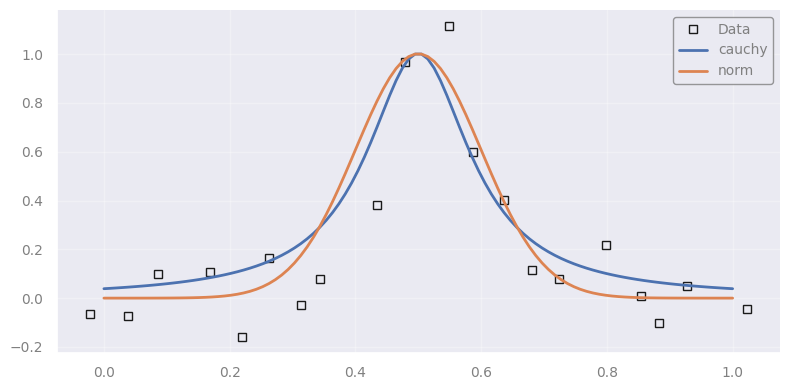


<h2><span class="fa fa-flash"></span> In-Class Coding Exercise </h2>

```{embed} icc_12-2
```

This notebook was adapted from a series of references:
+ [The emcee tutorial documentation](https://emcee.readthedocs.io/en/stable/tutorials/line/)
+ [The AstroStats School 2026 Documentation](https://astrostat-academy.github.io/astrostat-school-8/index.html)